<a href="https://colab.research.google.com/github/Andoniadou-Lab/PCP_sc_spatial/blob/main/London_team/Fig2A_Identifying_BRAF_V600E.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

This is a Google Colab / Jupyter Notebook, showing the identification of BRAF V600E mutations in our Papillary Craniopharyngioma single-cell datasets. Prior to this notebook, Cell Ranger was used to align the datasets.

Mounting Google Drive


In [ ]:
#mount drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!apt-get update
!apt-get install -y samtools

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:5 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [72.8 kB]
Get:9 https://cli.github.com/packages stable/main amd64 Packages [359 B]
Hit:10 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Get:11 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,244 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.2 MB]
Get:13 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [1,801 kB]
Get:14 http:/

In [ ]:
!samtools view -H /content/drive/MyDrive/pituitary_tumor_atlas/pcp_bams/OES21644390B/possorted_genome_bam.bam | grep -i "cellranger"


@PG	ID:cellranger	PN:Cell Ranger	VN:cellranger-8.0.1
@PG	ID:samtools	PN:samtools	PP:cellranger	VN:1.16.1	CL:samtools cat --threads 3 -b /mnt/d/BK/bk_tumor_data/OES21644390B_outs2/SC_RNA_COUNTER_CS/SC_MULTI_CORE/MULTI_GEM_WELL_PROCESSOR/COUNT_GEM_WELL_PROCESSOR/_BASIC_SC_RNA_COUNTER/WRITE_POS_BAM/fork0/join-u0b6912d5d4/files/pos_sorted_non_multiplexed.fofn -o /mnt/d/BK/bk_tumor_data/OES21644390B_outs2/SC_RNA_COUNTER_CS/SC_MULTI_CORE/MULTI_GEM_WELL_PROCESSOR/COUNT_GEM_WELL_PROCESSOR/_BASIC_SC_RNA_COUNTER/WRITE_POS_BAM/fork0/join-u0b6912d5d4/files/pos_sorted_non_multiplexed.bam


# Moving on to analysis. First installing scanpy and b2btrace (our custom made software for quickly identifying cells with mutant sequences)

In [ ]:
!pip install scanpy
!pip install b2btrace

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 188.8/188.8 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.0/40.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 108.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 376.9/376.9 kB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.1/225.1 kB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 121.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 5.9 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
ERROR: pip's dependency resolver does not currently take

In [ ]:
import os
folder = "/content/drive/MyDrive/pituitary_tumor_atlas/pcp_bams/"
all_files = []
for root, _, files in os.walk(folder):
        for file in files:
            if file.endswith(".bam"):
                all_files.append((os.path.join(root, file)))
samples = ["OES21644390B", "OES232911100B01","OES232243100B", "OES21644790B","OES232245100B01","OES231739100B","SRX28013270","SRX28013271","SRX28013272","SRX28013273"]

# Defining the mutant and wt sequence that corresponds to BRAF V600E.
###  To ensure the read is covered from either side, two sequences are defined covering the 5' and 3' ends of the variant and onwards.

### Running the workflow

In [ ]:
from b2btrace.b2btrace import run_workflow, create_regex_pattern, awk_template, run_search, create_results_df, umi_collapse, assign_genotype_to_umi, assign_genotype_to_barcode
import os
import pandas as pd
region_start = 140720000
region_end = 140920000
chromosome = "chr7"

dfs = []
for sample in samples:
  bam_path = f'/content/drive/MyDrive/pituitary_tumor_atlas/pcp_bams/{sample}/possorted_genome_bam.bam'
  wt = "A"
  mut = None
  target_pattern1 = ".CTGTAGCTAGACCAAAA"
  regex_for_awk,awk_python_regex_patterns = create_regex_pattern(target_pattern=target_pattern1)
  awk_script = awk_template(regex_for_awk)
  result = run_search(chromosome, region_start, region_end, bam_path,awk_script)
  df = create_results_df(result, awk_python_regex_patterns = awk_python_regex_patterns)
  df1, alleles = umi_collapse(df)


  target_pattern2 = "CTCCATCGAGATTTC."
  regex_for_awk,awk_python_regex_patterns = create_regex_pattern(target_pattern=target_pattern2)
  awk_script = awk_template(regex_for_awk)
  result = run_search(chromosome, region_start, region_end, bam_path,awk_script)
  df = create_results_df(result, awk_python_regex_patterns = awk_python_regex_patterns)
  df2, alleles = umi_collapse(df)

  #print whether len df1 and df2 are the same
  print("Chech this______________________________")
  print(len(df1),len(df2))
  df1 = pd.concat([df1, df2])
  df1 = df1.drop_duplicates(subset=['Barcode', 'UMI'])


  df = assign_genotype_to_umi(df1, wt=wt,query_subsequence=True)
  df = assign_genotype_to_barcode(df)
  df["sample"] = sample
  dfs.append(df)



Executing command:
samtools view /content/drive/MyDrive/pituitary_tumor_atlas/pcp_bams/OES21644390B/possorted_genome_bam.bam chr7:140720000-140920000 | awk '
    BEGIN { OFS="\t" } # Set output field separator to tab
    $10 ~ /.CTGTAGCTAGACCAAAA|AAAACCAGATCGATGTC.|.GACATCGATCTGGTTTT|TTTTGGTCTAGCTACAG./ {
        umi = "N/A";
        cb = "N/A";

        # Extract UMI and Cell Barcode
        for (i=12; i<=NF; i++) {
            if ($i ~ /^UB:Z:/) {
                umi = substr($i, 6);
            } else if ($i ~ /^CB:Z:/) {
                cb = substr($i, 6);
            }
        }

        # No need to determine matched_pattern_type in AWK anymore, Python will do it.
        # Print relevant fields
        if (umi != "N/A" && cb != "N/A") { # Only print if both UMI and CB found
            print cb, umi, $10, $11, $6; # CB, UMI, Aligned_Seq, Qual_Scores, CIGAR
        }
    }
    '


---Post-processing DataFrame---
Wildcard presence in patterns: True

--- Results DataFrame ---
     

In [ ]:
#concat dfs
df = pd.concat(dfs)
df["Genotype"].value_counts()

Genotype
WT-A     141
MUT-T     16
Name: count, dtype: int64

In [ ]:
#lowest Avg_Phred_Score
df["Avg_Phred_Score"].min()

'27.28'

In [ ]:
#saving the results
df.to_csv("/content/drive/MyDrive/pituitary_tumor_atlas/results/genotype_results_final_2026_09_16.csv", index=False)

In [ ]:
import scanpy as sc
adata_final = sc.read(f"/content/drive/MyDrive/pituitary_tumor_atlas/results/finalised_annotated_2026_06_17")

In [ ]:
#adjusting some sample names to match with adata object
#change OES232911100B01 to OES232911100B and OES232245100B01 to OES232245100B
df["sample"] = df["sample"].replace(["OES232911100B01", "OES232245100B01"], ["OES232911100B", "OES232245100B"])
#from Barcode remove -1 at the end
df["Barcode"] = df["Barcode"].str.replace("-1", "")

In [ ]:
#merge on name - "0" and dataset_id - dataset
table = adata_final.obs.merge(df, left_on=["0","dataset"], right_on=["Barcode","sample"], how="left")
#remove where barcode, dataset_id is duplicate
#sort by genotype
table.sort_values(["Genotype"],inplace=True)
table.drop_duplicates(["0","dataset"],inplace=True)
#sort by index
table.sort_index(inplace=True)
table.reset_index(drop=True, inplace=True)

In [ ]:
table["Genotype"].unique()

<ArrowStringArray>
[nan, 'WT-A', 'MUT-T']
Length: 3, dtype: str

In [ ]:
adata_final.obs = table

/usr/lib/python3.13/functools.py:934: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [ ]:
mutant_cells = table[table["Genotype"]=="MUT-T"]["Barcode"].values.tolist()
healthy_cells = table[table["Genotype"]=="WT-A"]["Barcode"].values.tolist()

# Generating Figure

/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list
/usr/local/lib/python3.13/dist-packages/scanpy/plotting/_utils.py:509: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[f"{value_to_plot}_colors"] = colors_list


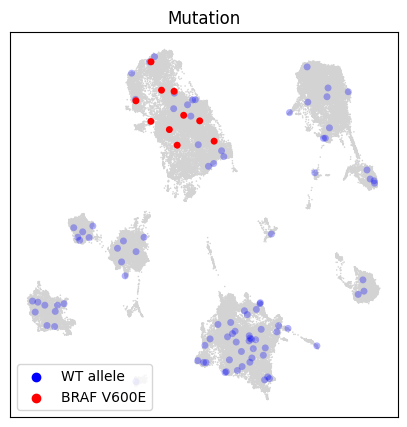

In [ ]:
import scanpy as sc
import matplotlib.pyplot as plt

# Assuming adata_final and cells are already defined

# Create a new column for highlighting the specific cell. If in mutant_cells make it Mutant, if in Healthy make it Healthy, if neither make it Unknown
adata_final.obs['Mutation'] = 'Unknown'

adata_final.obs.loc[adata_final.obs["0"].isin(mutant_cells), 'Mutation'] = 'BRAF V600E'
adata_final.obs.loc[adata_final.obs["0"].isin(healthy_cells), 'Mutation'] = 'WT allele'

# Set up the plot
fig, ax = plt.subplots(figsize=(5, 5))

# Plot 1: All cells with grey color
ax = sc.pl.umap(adata_final, palette='lightgrey', show=False, ax=ax, size=5)

# Plot 2: Only Healthy cells with blue color (This will be plotted first)
sc.pl.umap(adata_final[adata_final.obs["Mutation"] == 'WT allele'],
           color='Mutation',
           ax=ax,
           legend_loc="lower left",
           sort_order=True,
           palette=['blue'],
           size=100, show=False, alpha=0.3)


# Plot 3: Only Mutant cells with red color (This will be plotted last and appear above Healthy cells)
sc.pl.umap(adata_final[adata_final.obs["Mutation"] == 'BRAF V600E'],
           color='Mutation',
           ax=ax,
           legend_loc="lower left",
           sort_order=True,
           palette=['red'],
           size=100, show=False)

# Remove x and y labels
ax.set_xlabel("")
ax.set_ylabel("")

#save
# Save the figure as SVG
plt.savefig("/content/drive/MyDrive/human_pcp/mutant_cells_umap_2026_09_16.svg", format="svg")

#save fig 300 dpi png
plt.savefig("/content/drive/MyDrive/human_pcp/mutant_cells_umap_2026_09_16.png", dpi=300)

In [ ]:
#confusion table of Mutant and broad_cluster
table = pd.crosstab(adata_final.obs["Mutation"], adata_final.obs["broad_cluster"])
#only keep Healthy and Mutant row
table = table.loc[["WT allele", "BRAF V600E"]]
#only keep Healthy and Mutant column
table

broad_cluster,CD4 T-cells,CD4 T-regs,CD8 cytotoxic T-cells,Dendritic cells,Endothelial cells,Epithelial cells,M1 Macrophages,M2 Macrophages,Mast cells,Mesenchymal cells,Naive B-cells,Neutrophils,Pericytes,Pituicytes,Plasma cells,Stem-like cells,pDC
Mutation,,,,,,,,,,,,,,,,,
WT allele,5,1,7,7,9,5,3,30,1,6,3,1,6,0,0,10,1
BRAF V600E,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,9,0


In [ ]:
#probability of observing all 5 mutant cells in the stem cell compartment
import numpy as np
total = np.sum(table.values.flatten())
mut_sc = 10

import scipy.stats
scipy.stats.hypergeom.pmf(mut_sc,total,19,mut_sc)


np.float64(3.2021814851255264e-09)

In [ ]:
!pip freeze

absl-py==1.4.0
accelerate==1.7.0
aiofiles==24.1.0
aiohappyeyeballs==2.6.1
aiohttp==3.11.15
aiosignal==1.3.2
alabaster==1.0.0
albucore==0.0.24
albumentations==2.0.8
ale-py==0.11.1
altair==5.5.0
anndata==0.11.4
annotated-types==0.7.0
antlr4-python3-runtime==4.9.3
anyio==4.9.0
argon2-cffi==25.1.0
argon2-cffi-bindings==21.2.0
array-api-compat==1.12.0
array_record==0.7.2
arviz==0.21.0
astropy==7.1.0
astropy-iers-data==0.2025.6.2.0.38.23
astunparse==1.6.3
atpublic==5.1
attrs==25.3.0
audioread==3.0.1
autograd==1.8.0
b2btrace==0.0.4
babel==2.17.0
backcall==0.2.0
backports.tarfile==1.2.0
beautifulsoup4==4.13.4
betterproto==2.0.0b6
bigframes==2.5.0
bigquery-magics==0.9.0
bleach==6.2.0
blinker==1.9.0
blis==1.3.0
blobfile==3.0.0
blosc2==3.3.4
bokeh==3.7.3
Bottleneck==1.4.2
bqplot==0.12.45
branca==0.8.1
build==1.2.2.post1
CacheControl==0.14.3
cachetools==5.5.2
catalogue==2.0.10
certifi==2025.4.26
cffi==1.17.1
chardet==5.2.0
charset-normalizer==3.4.2
chex==0.1.89
clarabel==0.11.0
click==8.2.1
cloudp